In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Dropout, Flatten, Dense
)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
plt.rcParams['figure.figsize'] = (10, 10)

In [3]:
(x_train_all, y_train_all), (x_test, y_test) = mnist.load_data()

#10 000 изображений для обучения
all_indices = np.arange(len(y_train_all))

train_indices, remaining_indices = train_test_split(all_indices, train_size=10_000, random_state=SEED,  stratify=y_train_all)

val_indices, _ = train_test_split( remaining_indices, train_size=2_000, random_state=SEED, stratify=y_train_all[remaining_indices])

# Нормализация изображения
x_train = x_train_all[train_indices].astype(np.float32) / 255.0
y_train = y_train_all[train_indices]

x_val = x_train_all[val_indices].astype(np.float32) / 255.0
y_val = y_train_all[val_indices]

x_test = x_test.astype(np.float32) / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 20s 2us/step


### Дальше нужно привести данные в пригодную для каждого метода структуру

In [4]:
# Для Random Forest и SVM
X_train = x_train.reshape(len(x_train), -1)
X_test = x_test.reshape(len(x_test), -1)

# Для CNN
x_train_cnn = x_train[..., np.newaxis]
x_val_cnn = x_val[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

print('Обучающая:', x_train.shape)
print('Проверочная CNN:', x_val.shape)
print('Тестовая :', x_test.shape)
print('Форма данных для RF / SVM:', X_train.shape)
print('Форма данных для CNN:', x_train_cnn.shape)

Обучающая: (10000, 28, 28)
Проверочная CNN: (2000, 28, 28)
Тестовая : (10000, 28, 28)
Форма данных для RF / SVM: (10000, 784)
Форма данных для CNN: (10000, 28, 28, 1)


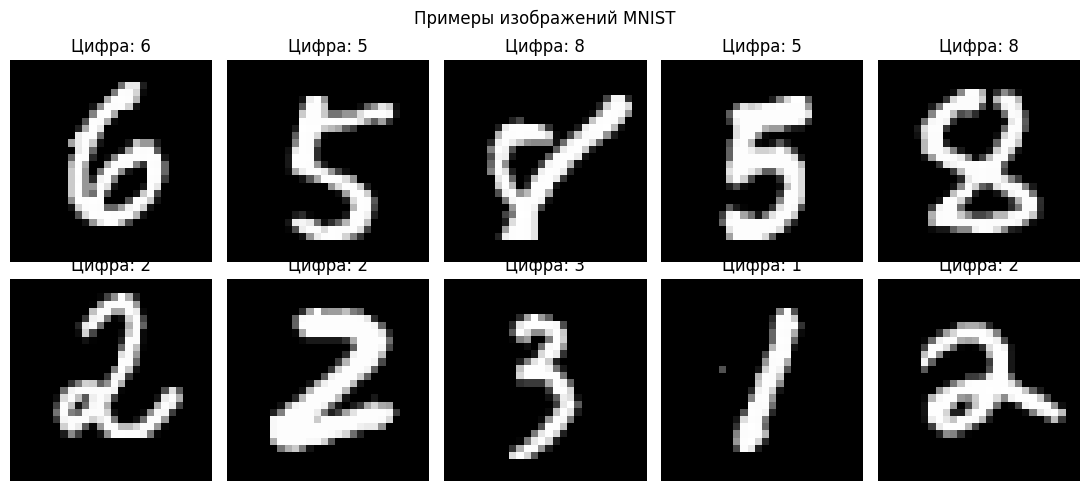

Количество изображений каждой цифры:
0     987
1    1124
2     993
3    1022
4     974
5     904
6     986
7    1044
8     975
9     991


In [5]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(f'Цифра: {y_train[i]}')
    ax.axis('off')

plt.suptitle('Примеры изображений MNIST')
plt.tight_layout()
plt.show()

print('Количество изображений каждой цифры:')
print(pd.Series(y_train).value_counts().sort_index().to_string())

In [6]:
rf = RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=-1)

start = time.perf_counter()
rf.fit(X_train, y_train)
rf_train_time = time.perf_counter() - start
rf_pred = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

print(f'Random Forest — Accuracy: {rf_acc:.4f} ({rf_acc:.2%})')
print(f'Время обучения: {rf_train_time:.2f} с')

Random Forest — Accuracy: 0.9512 (95.12%)
Время обучения: 0.52 с


In [7]:
svm_model = SVC(kernel='rbf',  C=5,  gamma='scale')

start = time.perf_counter()
svm_model.fit(X_train, y_train)
svm_train_time = time.perf_counter() - start
svm_pred = svm_model.predict(X_test)
svm_acc = accuracy_score(y_test, svm_pred)

       Модель  Accuracy  Время обучения, с
Random Forest    0.9512             0.5221
    SVM (RBF)    0.9696             4.1911


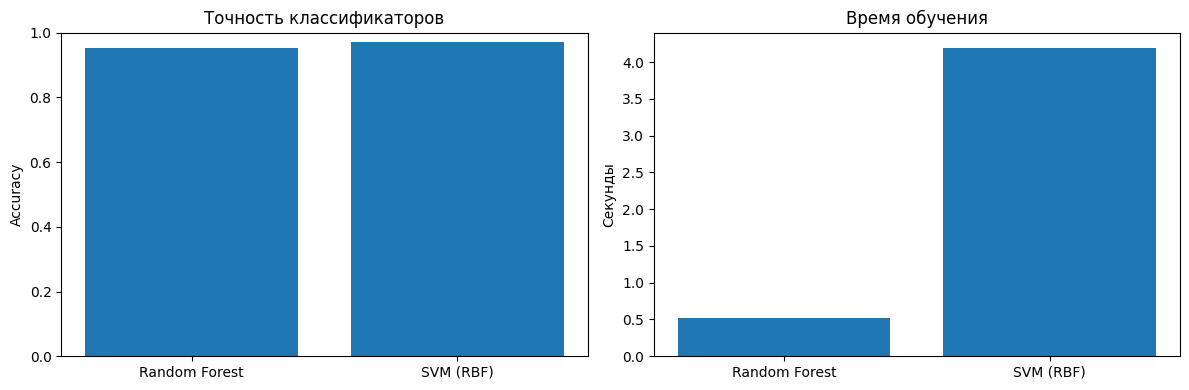

In [9]:
compare_classic = pd.DataFrame({
    'Модель': ['Random Forest', 'SVM (RBF)'],
    'Accuracy': [rf_acc, svm_acc],
    'Время обучения, с': [ rf_train_time, svm_train_time]
})

print(compare_classic.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    compare_classic['Модель'],
    compare_classic['Accuracy']
)
axes[0].set_title('Точность классификаторов')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1)

axes[1].bar(
    compare_classic['Модель'],
    compare_classic['Время обучения, с']
)
axes[1].set_title('Время обучения')
axes[1].set_ylabel('Секунды')

plt.tight_layout()
plt.show()


In [10]:
cnn = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Dropout(0.25),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(10, activation='softmax')
])

In [12]:
cnn.compile( optimizer='adam',  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

cnn.summary()

start = time.perf_counter()

history = cnn.fit( x_train_cnn, y_train, epochs=5, batch_size=128, validation_data=(x_val_cnn, y_val), verbose=1)

cnn_train_time = time.perf_counter() - start

cnn_test_loss, cnn_acc = cnn.evaluate( x_test_cnn, y_test, verbose=0)

cnn_prob = cnn.predict( x_test_cnn, batch_size=256, verbose=0)

cnn_pred = np.argmax(cnn_prob, axis=1)

print(f'CNN — Accuracy: {cnn_acc:.4f} ({cnn_acc:.2%})')
print(f'CNN — Loss: {cnn_test_loss:.4f}')
print(f'Время обучения CNN: {cnn_train_time:.2f} с')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7300 - loss: 0.8530 - val_accuracy: 0.9385 - val_loss: 0.2179
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9190 - loss: 0.2698 - val_accuracy: 0.9595 - val_loss: 0.1386
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9442 - loss: 0.1841 - val_accuracy: 0.9715 - val_loss: 0.1069
Epoch 4/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9532 - loss: 0.1517 - val_accuracy: 0.9755 - val_loss: 0.0894
Epoch 5/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9632 - loss: 0.1157 - val_accuracy: 0.9755 - val_loss: 0.0867
CNN — Accuracy: 0.9771 (97.71%)
CNN — Loss: 0.0714
Время обучения CNN: 5.59 с


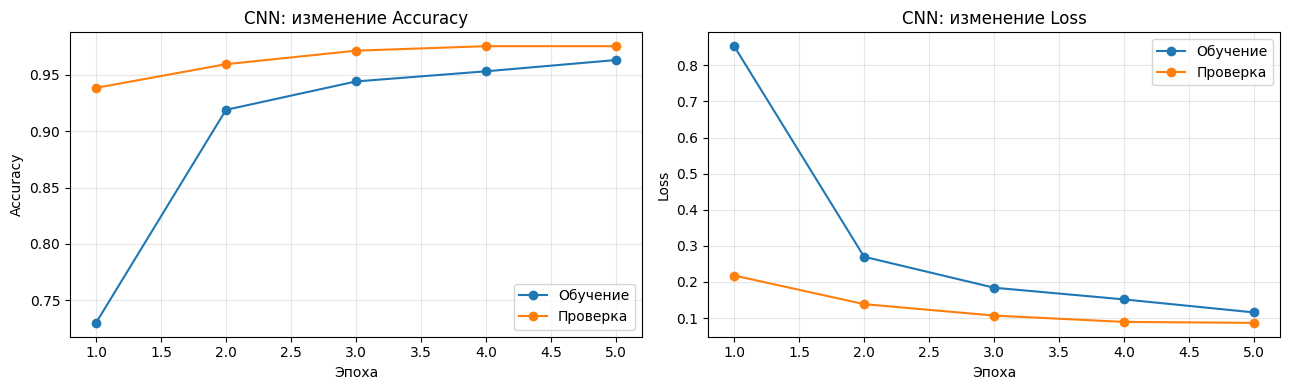

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

epochs = np.arange(1, len(history.history['loss']) + 1)

axes[0].plot( epochs, history.history['accuracy'], marker='o', label='Обучение')

axes[0].plot( epochs, history.history['val_accuracy'], marker='o', label='Проверка')

axes[0].set_title('CNN: изменение Accuracy')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Accuracy')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs,  history.history['loss'], marker='o',  label='Обучение')

axes[1].plot(epochs,  history.history['val_loss'],  marker='o',  label='Проверка')

axes[1].set_title('CNN: изменение Loss')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Loss')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

